In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [27]:
import os

imgpath = '/content/drive/MyDrive/의료영상처리/DIP4E'

file_path = imgpath + '/hidden-symbols.tif'

print(os.path.exists(file_path))

True


(256, 256) uint8


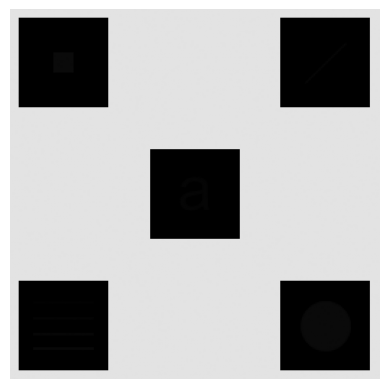

In [28]:
f = plt.imread(file_path)

print(f.shape, f.dtype)

plt.imshow(f, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()

## Histogram Processing

In [ ]:
f = plt.imread(imgpath+'/pollen-lowcontrast.tif')
print(f.shape,f.dtype)

(500, 500) uint8


- histogram equalization

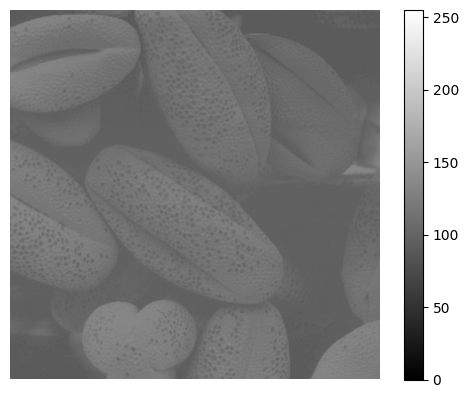

In [ ]:
plt.imshow(f, cmap = 'gray', vmin=0, vmax=255)
plt.axis('off')
plt.colorbar()
plt.show()

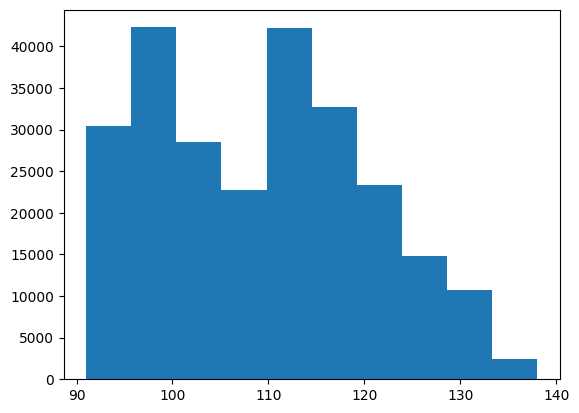

In [ ]:
plt.hist(f.flatten())
plt.show()

In [9]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

In [ ]:
f_eq = histogram_equalization(f)
plt.hist(f_eq.flatten())
plt.show()

In [ ]:
plt.imshow(f_eq, cmap = 'gray', vmin=0, vmax=255)
plt.axis('off')
plt.colorbar()
plt.show()

- local histogram equalization

In [ ]:
f = plt.imread(imgpath+'/hidden-symbols.tif')
print(f.shape,f.dtype)

(256, 256) uint8


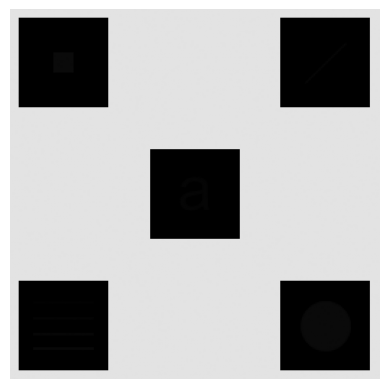

In [ ]:
plt.imshow(f,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
f_eq = histogram_equalization(f)
plt.imshow(f_eq,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

### Exercise 1.
- 아래의 예는 local histogram equalization을 수행한다.
- 적절한 neighborhood size N을 찾아서 숨겨진 기호들을 모두 확인해보자.
- plt.imshow의 vim, vmax를 수정하여서도 숨겨진 기호들을 확인할 수 있으나, 본 실습에서는 vmax=255로 고정하여 histogram processing을 통해 숨겨진 기호들을 확인하자.

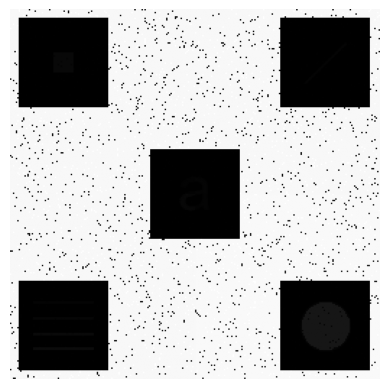

In [29]:
N = 128
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()


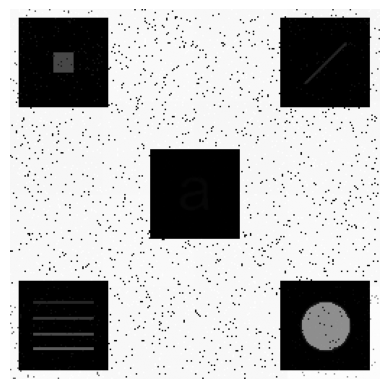

In [30]:
N = 64
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

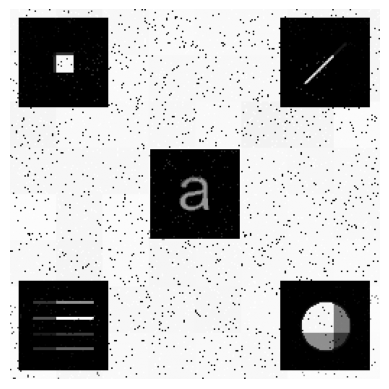

In [31]:
N = 32
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

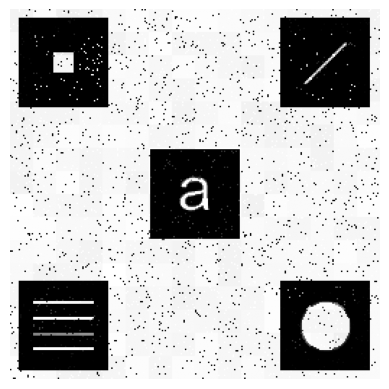

In [32]:
N = 16
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

Exercise 1. 결과 분석

Local Histogram Equalization에서 neighborhood size인 N을 128, 64, 32, 16으로 변경하며 결과를 비교하였다. N이 작아질수록 숨겨진 사각형, 대각선, 문자, 수평선 및 원형 패턴이 더 뚜렷해졌다. 특히 N=16에서 기호를 가장 명확하게 확인할 수 있었다. 다만 배경의 미세한 밝기 변화도 함께 강조되는 현상이 나타났다.

# Linear Spatial Filtering
## 2D convolution

In [ ]:
import scipy.signal as signal
from skimage import io

In [ ]:
f = io.imread('https://press.hufs.ac.kr/data/file/gift/6f5a7159a604fe7de30498fd76c8741d_JIWi6Gj9_d6e43320ba8ee4ac452deadd5246a2d6db29e853.jpg',as_gray=True)[::2,::2]
print(f.shape,f.dtype)

(500, 500) float64


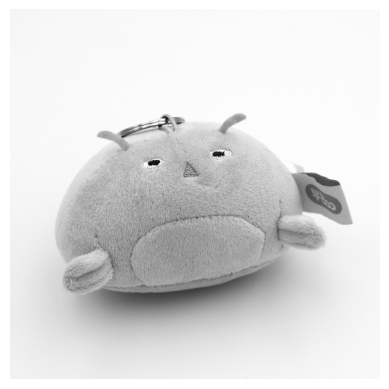

In [ ]:
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
w = np.random.randn(3,3)
#w = np.array([[-1,0,1],
#              [-2,0,2],
#              [-1,0,1]])
print(w)

[[-1.81012859  0.75613237  0.68339257]
 [ 0.06399962 -0.98234732  0.00781321]
 [-1.89691551  0.08972406  0.03099641]]


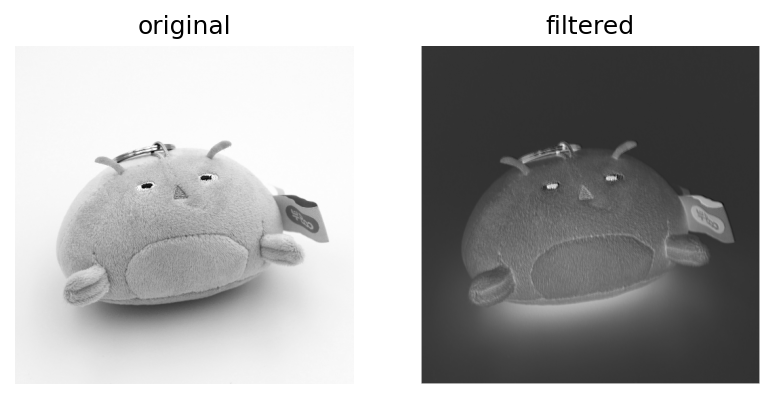

In [ ]:
sz0,sz1 = f.shape
y = np.zeros_like(f)
for i in np.arange(1,sz0-1):
  for j in np.arange(1,sz1-1):
    y[i,j] = np.sum(f[i-1:i+2,j-1:j+2]*w[::-1,::-1])

plt.figure(dpi=150)
plt.subplot(1,2,1)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('original')
plt.subplot(1,2,2)
plt.imshow(y,cmap='gray')
plt.axis('off')
plt.title('filtered')
plt.show()

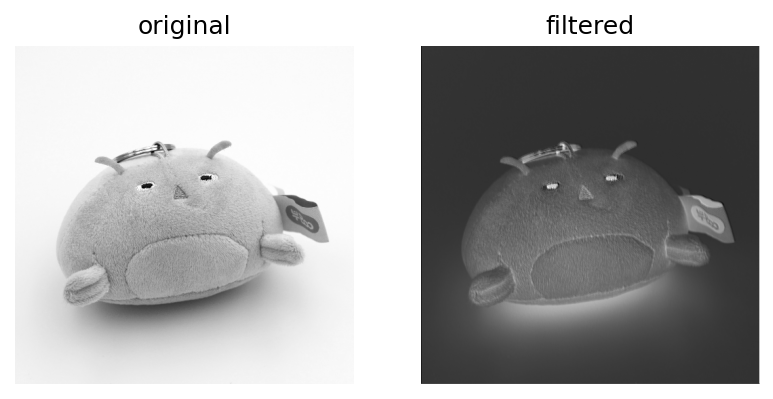

In [ ]:
y = signal.convolve2d(f,w,mode='same')
y.shape
plt.figure(dpi=150)
plt.subplot(121)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('original')
plt.subplot(122)
plt.imshow(y,cmap='gray')
plt.axis('off')
plt.title('filtered')
plt.show()

## low pass filtering - box kernel

In [ ]:
w = np.ones((3,3))
w = w/np.sum(w)
print(w)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


In [ ]:
yb = signal.convolve2d(f,w,mode='same')


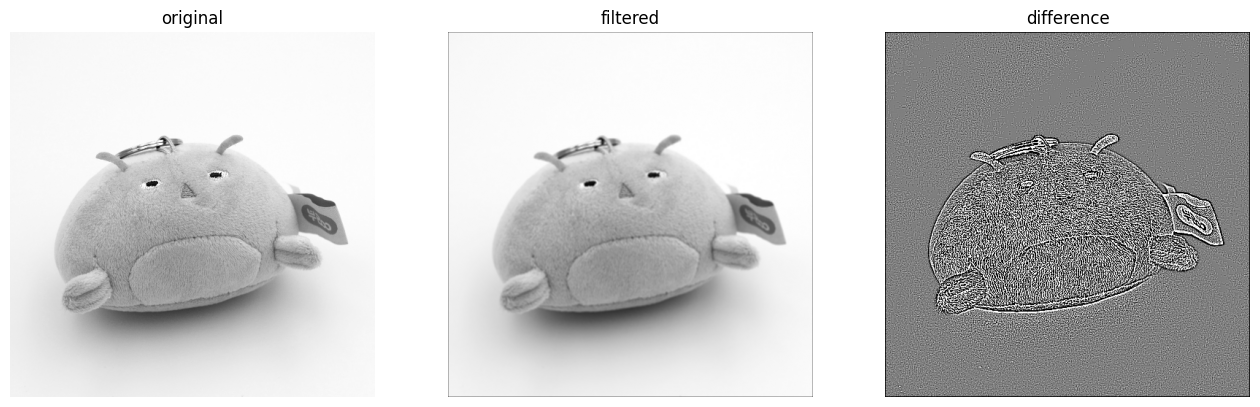

In [ ]:
plt.figure(figsize=(16,9))
plt.subplot(1,3,1)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('original')
plt.subplot(1,3,2)
plt.imshow(yb,cmap='gray')
plt.axis('off')
plt.title('filtered')
plt.subplot(1,3,3)
plt.imshow(yb-f,cmap='gray',vmin=-.01,vmax=.01)
plt.axis('off')
plt.title('difference')
plt.show()

In [ ]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  y_b = signal.convolve2d(f,wb,mode='same')

  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

## lowpass filtering - Gaussian kernel

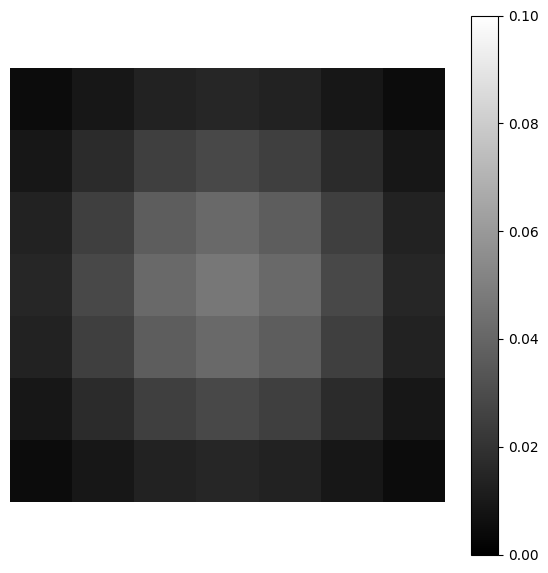

In [ ]:
N = 3
std = 2
s = np.arange(-N,N+1,1)
t = np.arange(-N,N+1,1)
S,T = np.meshgrid(s,t)
wg = np.exp(-(S**2+T**2)/(2*std*std))
wg = wg/np.sum(wg)

plt.figure(figsize=(7,7))
plt.imshow(wg,vmin=0,vmax=0.1,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

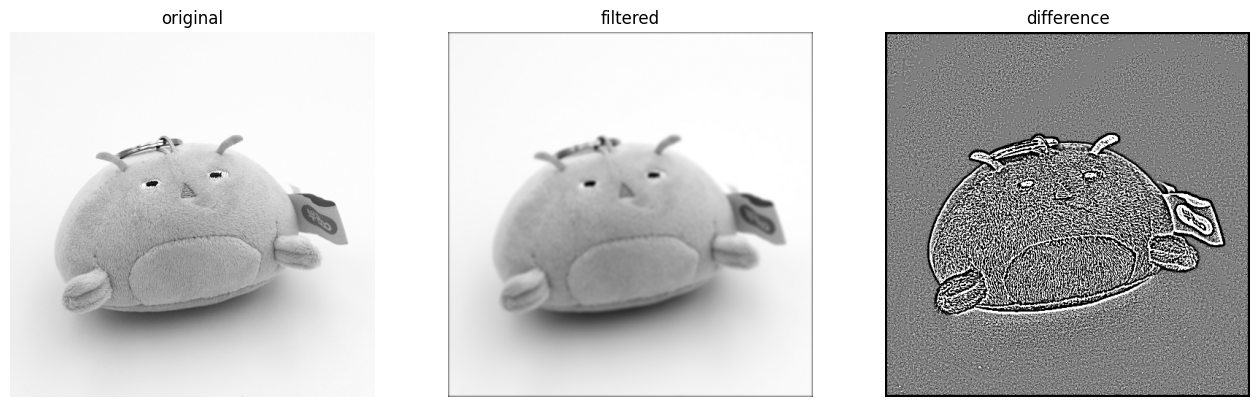

In [ ]:
y_g = signal.convolve2d(f,wg,mode='same')

plt.figure(figsize=(16,9))
plt.subplot(1,3,1)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('original')
plt.subplot(1,3,2)
plt.imshow(y_g,cmap='gray')
plt.axis('off')
plt.title('filtered')
plt.subplot(1,3,3)
plt.imshow(y_g-f,cmap='gray',vmin=-.01,vmax=.01)
plt.axis('off')
plt.title('difference')
plt.show()

In [ ]:
s = np.arange(-13,14,1)
t = np.arange(-13,14,1)
S,T = np.meshgrid(s,t)

for std in np.array([1,3,5,7]):
  wg = np.exp(-(S**2+T**2)/(2*std*std))
  wg = wg/np.sum(wg)

  y_g = signal.convolve2d(f,wg,mode='same')

  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_g,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - sigma:{std}')
  plt.subplot(1,3,3)
  plt.imshow(y_g-f,cmap='gray',vmin=-.01, vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

### Exercise 2.
- 직접 찍은 사진을 grayscale image로 불러와서, kernel size를 3x3, 7x7, 15x15, 30x30 으로 늘려가며 box kernel을 정의하여 LPF를 진행한 결과를 출력하고 kernel size에 따른 연산시간의 차이를 확인하자.

In [24]:
f = f_photo
f = np.rot90(f, k=3)
print(f.shape, f.dtype)

(400, 300) float64


In [25]:
import time

computation time =  0.014673471450805664  sec


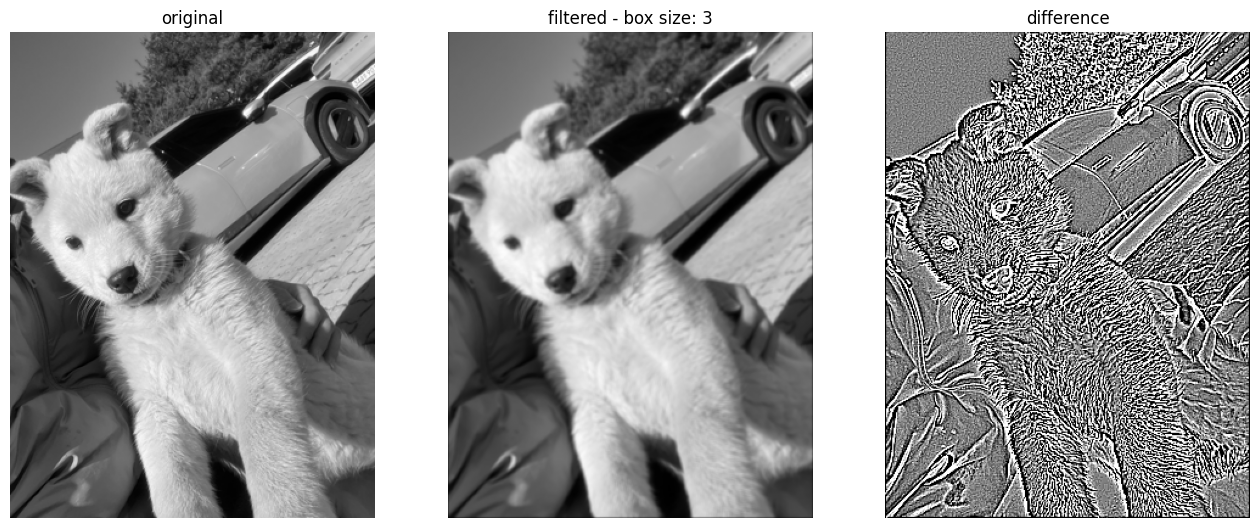

computation time =  0.039060354232788086  sec


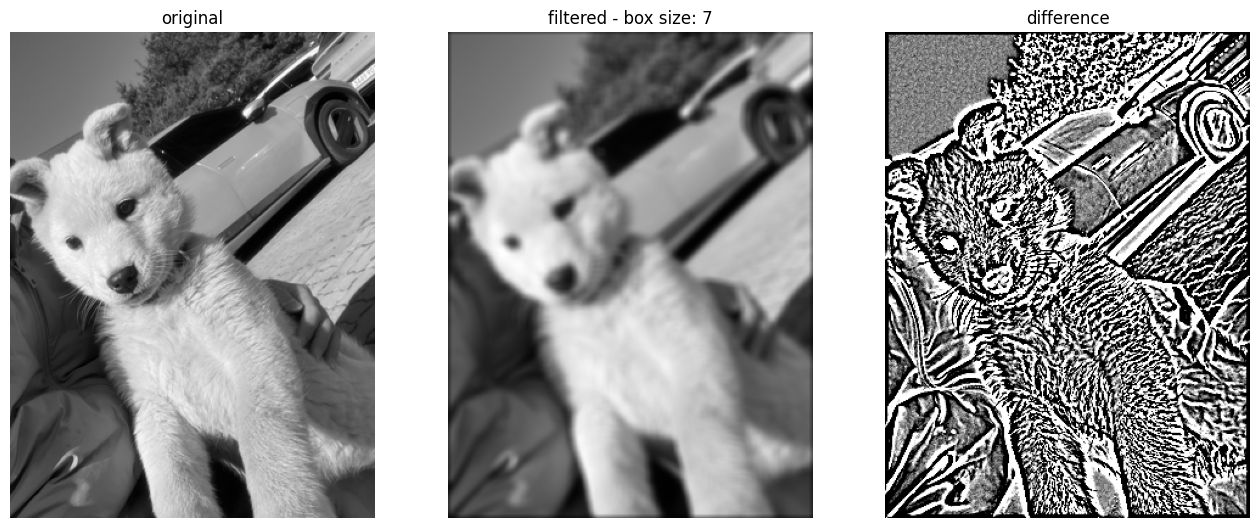

computation time =  0.12374114990234375  sec


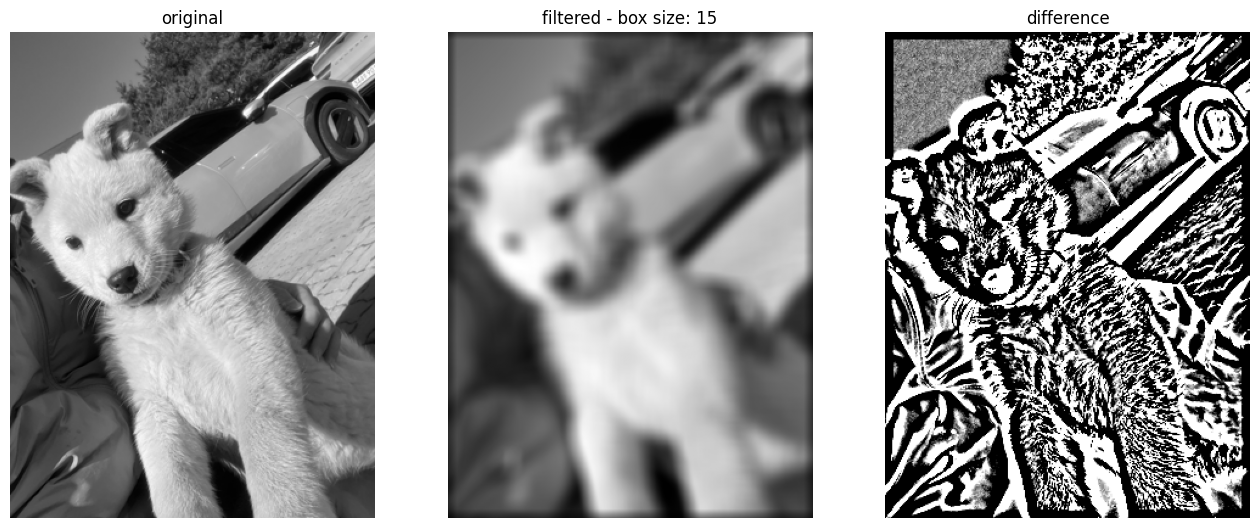

computation time =  0.4542570114135742  sec


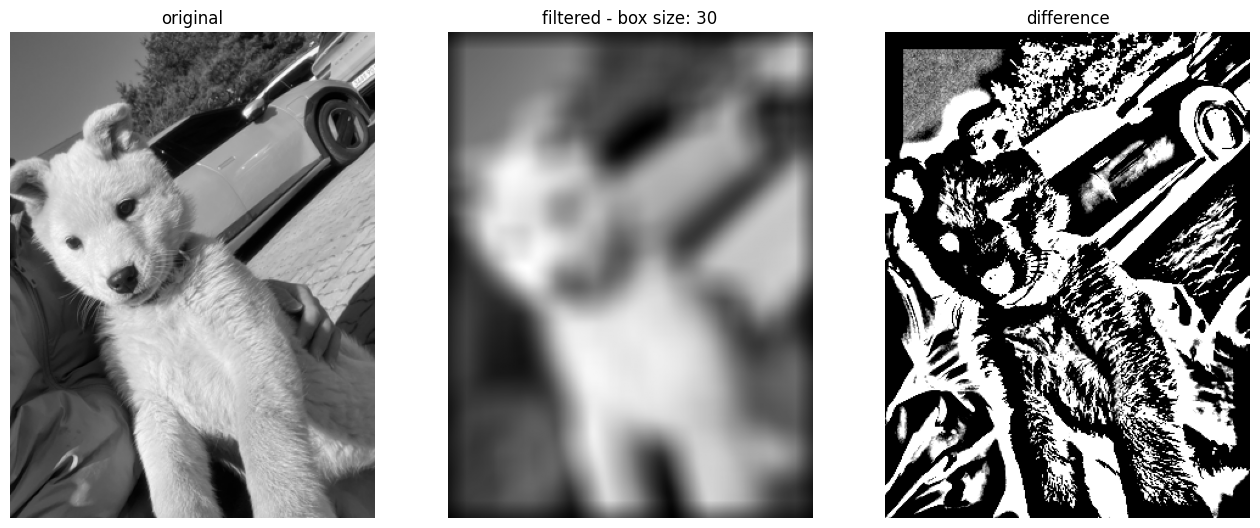

In [26]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

Exercise 2. 결과 분석

본인이 촬영한 사진을 Grayscale 영상으로 변환한 후, Box Filter를 이용하여 Low-Pass Filtering(LPF)을 수행하였다. Kernel 크기를 3×3, 7×7, 15×15, 30×30으로 변경하면서 원본 영상과 필터링 결과를 비교하였다.

실험 결과, Kernel 크기가 증가할수록 영상의 Blurring 효과가 강해지는 것을 확인하였다. 3×3 Kernel에서는 원본의 세부 구조와 경계가 비교적 잘 유지되었으나, 15×15와 30×30 Kernel에서는 물체의 윤곽과 세부 정보가 점차 흐려졌다. 이는 Kernel 크기가 커질수록 더 넓은 영역의 픽셀 밝기값을 평균화하기 때문이다.

연산시간은 3×3에서 약 0.0054초, 7×7에서 0.0172초, 15×15에서 0.0640초, 30×30에서 0.2412초로 증가하였다. 이를 통해 Kernel 크기가 증가하면 연산량도 증가한다는 것을 확인할 수 있었다.

따라서 LPF는 영상의 고주파 성분을 감소시켜 잡음이나 미세한 밝기 변화를 완화할 수 있지만, 동시에 경계와 세부 구조가 손실될 수 있다는 한계가 있다.

# highpass filtering



In [ ]:
f = plt.imread(os.path.join(imgpath,'moon-blurred.tif'))
print(f.shape,f.dtype)
plt.figure(figsize=(10,10))
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('image')
plt.colorbar()
plt.show()

# Laplacian Kernel (2nd order diff.)


In [ ]:
w1 = np.array([[0,1,0],[1,-4.,1],[0,1,0]])
w2 = np.array([[0,-1,0],[-1,4.,-1],[0,-1,0]])

w3 = np.array([[1,1,1],[1,-8.,1],[1,1,1]])
w4 = np.array([[-1,-1,-1],[-1,8.,-1],[-1,-1,-1]])

print(w1)
print(w2)
print(w3)
print(w4)

[[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]
[[ 0. -1.  0.]
 [-1.  4. -1.]
 [ 0. -1.  0.]]
[[ 1.  1.  1.]
 [ 1. -8.  1.]
 [ 1.  1.  1.]]
[[-1. -1. -1.]
 [-1.  8. -1.]
 [-1. -1. -1.]]


In [ ]:
y = signal.convolve2d(f,w2,mode='same')
y.shape
plt.figure(figsize=(16,8))
plt.subplot(121)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(122)
plt.imshow(y,cmap='gray',vmin=-16,vmax=16)
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()

### Exercise 3.
- highpass filtering의 결과를 활용하여 blurred image를 sharp하게 개선시켜 보자.
- 자신만의 blurred image를 가져와서, Laplacian kernel을 통한 highpass filtering을 진행하고 이를 이용하여 원본영상의 sharpness를 증대시켜보자.
- w 및 c를 적절하게 변화시켜 가면서 결과를 확인하자.

In [15]:
from google.colab import files

uploaded_blur = files.upload()
blur_name = next(iter(uploaded_blur))

Saving KakaoTalk_Photo_2026-10-12-23-12-09.jpeg to KakaoTalk_Photo_2026-10-12-23-12-09.jpeg


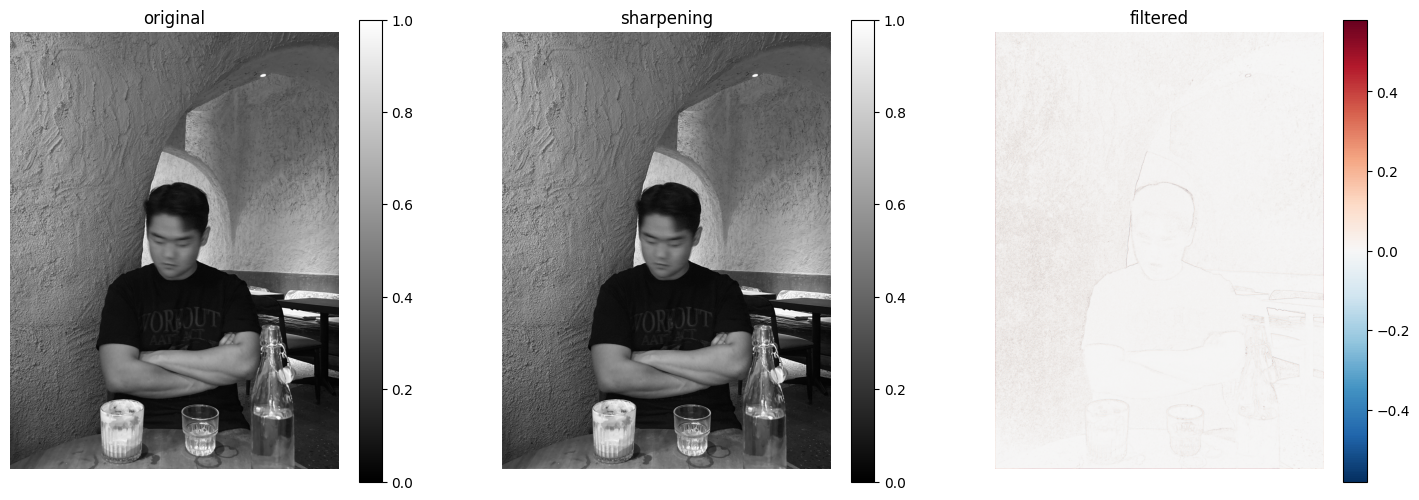

In [33]:
from skimage import io
import scipy.signal as signal

f = io.imread(blur_name, as_gray=True)
f = np.rot90(f, k=3)

w = np.array([[0,-1,0],[-1,4.,-1],[0,-1,0]])
y = signal.convolve2d(f,w,mode='same')
c = 1.0
g = f + c*(y)

plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f, cmap='gray', vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('original')

plt.subplot(132)
plt.imshow(np.clip(g, 0, 1),
           cmap='gray', vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('sharpening')

plt.subplot(133)
plt.imshow(
    y,cmap='RdBu_r',
    vmin=-0.5*np.max(np.abs(y)),
    vmax=0.5*np.max(np.abs(y))
)
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()

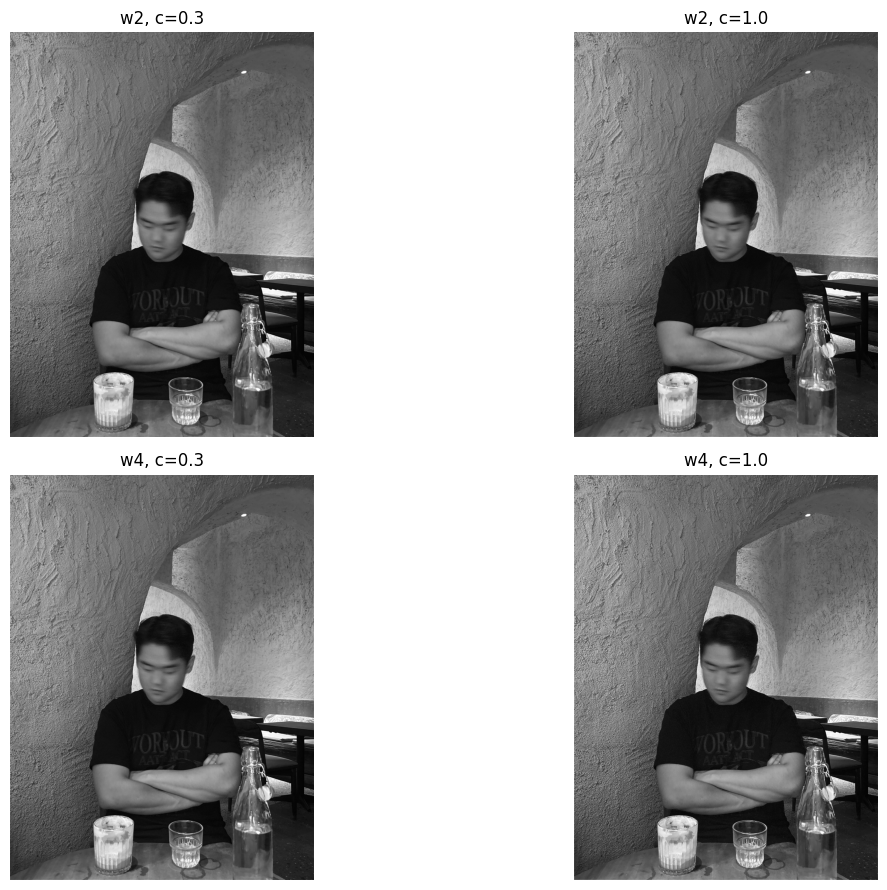

In [34]:
# Exercise 3 - Comparison of w and c

w2 = np.array([[0,-1,0],
               [-1,4,-1],
               [0,-1,0]])

w4 = np.array([[-1,-1,-1],
               [-1,8,-1],
               [-1,-1,-1]])

plt.figure(figsize=(14,9))

for i, (name, w) in enumerate([('w2', w2), ('w4', w4)]):
    y = signal.convolve2d(f, w, mode='same')

    for j, c in enumerate([0.3, 1.0]):
        g = f + c*y

        plt.subplot(2, 2, i*2+j+1)
        plt.imshow(np.clip(g, 0, 1),
                   cmap='gray', vmin=0, vmax=1)
        plt.title(f'{name}, c={c}')
        plt.axis('off')

plt.tight_layout()
plt.show()

Exercise 3. 결과 분석

흐릿한 사진을 Grayscale 영상으로 변환한 후, Laplacian Kernel을 이용하여 High-Pass Filtering(HPF)과 Sharpening을 수행하였다.

Laplacian Filter를 적용하여 영상의 밝기가 급격하게 변화하는 경계 부분을 추출하였으며, 추출된 고주파 성분을 원본 영상에 더하는 방식인 g = f + c × y를 이용하여 Sharpening을 진행하였다. 여기서 c는 고주파 성분을 원본 영상에 반영하는 정도를 결정하는 계수이며, 이번 실험에서는 c = 1.0을 사용하였다.

실험 결과, Sharpening 영상에서는 원본과 비교하여 인물의 윤곽과 주변 사물의 경계가 일부 강조되는 것을 확인하였다. 다만 전체적인 변화가 크지는 않았으며, Laplacian으로 추출한 고주파 성분에서도 주로 경계 부분의 변화가 관찰되었다.

또한 Original과 Sharpening 영상의 표시 밝기 범위를 동일하게 설정하여 필터 적용 전후를 비교하였다.

이 실험을 통해 HPF가 영상의 경계와 세부 구조를 강조하는 데 활용될 수 있음을 확인하였다. 그러나 Sharpening은 이미 손실된 정보를 완전히 복원하는 방법은 아니며, 계수 c가 지나치게 커질 경우 잡음이나 불필요한 경계가 함께 강조될 수 있으므로 적절한 파라미터 설정이 중요하다.

추가적으로 Laplacian Kernel의 종류(w2, w4)와 Sharpening 계수(c=0.3, 1.0)를 변경하며 결과를 비교하였다. w2는 상하좌우 4방향 이웃 픽셀을 활용하고, w4는 대각선을 포함한 8방향 이웃 픽셀을 활용한다. 또한 c 값이 커질수록 추출된 고주파 성분이 원본 영상에 더 강하게 반영된다. 이를 통해 Kernel의 구조와 계수에 따라 경계 강조 정도가 달라질 수 있으며, 과도한 Sharpening은 잡음과 부자연스러운 경계를 증가시킬 수 있음을 확인하고자 하였다.

## Sobel (1st order diff.)

In [ ]:
sobel1 = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
sobel2 = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(sobel1)
print(sobel2)

[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]


In [ ]:
g1 = signal.convolve2d(f,sobel1,mode='same')
g2 = signal.convolve2d(f,sobel2,mode='same')
G = np.sqrt(g1**2+g2**2)

plt.figure(figsize=(18,6))
plt.subplot(141)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(142)
plt.imshow(g1,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gy')
plt.subplot(143)
plt.imshow(g2,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gx')
plt.subplot(144)
plt.imshow(G,cmap='gray',vmin=0,vmax=255)
plt.colorbar()
plt.axis('off')
plt.title('magnitude of gradient')
plt.show()

In [ ]:
f = plt.imread(os.path.join(imgpath,'testpattern512.tif'))

g1 = signal.convolve2d(f,sobel1,mode='same')
g2 = signal.convolve2d(f,sobel2,mode='same')
G = np.sqrt(g1**2+g2**2)

plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g1,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gy')
plt.subplot(133)
plt.imshow(g2,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gx')
plt.show()


In [ ]:
G_ = np.abs(g1) + np.abs(g2)
plt.figure(figsize=(18,6))

plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')

plt.subplot(132)
plt.imshow(G,cmap='gray',vmin=0,vmax=255)
plt.colorbar()
plt.axis('off')
plt.title('|| G ||')

plt.subplot(133)
plt.imshow(G_,cmap='gray',vmin=0,vmax=255)
plt.colorbar()
plt.axis('off')
plt.title('~ || G ||')

plt.show()


# Lab00 Exercise - CT Registration Comparison

In [36]:
%pip install -q nibabel

import nibabel as nib
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

Saving reg-15.nii.gz to reg-15.nii.gz
Saving volume-covid19-A-0700_day000.nii.gz to volume-covid19-A-0700_day000.nii (1).gz
Saving volume-covid19-A-0700_day015.nii.gz to volume-covid19-A-0700_day015.nii.gz


Day000: (512, 512, 70)
Day015: (512, 512, 67)
Registered: (512, 512, 67)


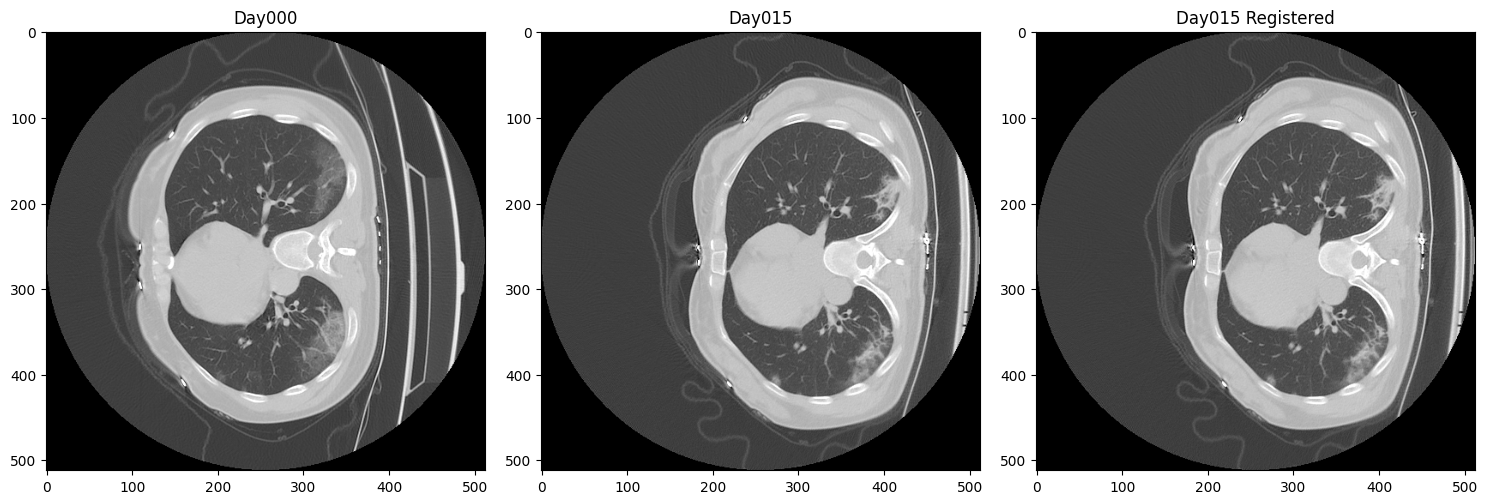

In [37]:
ct_base = nib.load(
    'volume-covid19-A-0700_day000.nii.gz'
).get_fdata()

ct_FU = nib.load(
    'volume-covid19-A-0700_day015.nii.gz'
).get_fdata()

ct_FU_reg = nib.load(
    'reg-15.nii.gz'
).get_fdata()

print('Day000:', ct_base.shape)
print('Day015:', ct_FU.shape)
print('Registered:', ct_FU_reg.shape)

plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(ct_base[:,:,30],
           vmin=-1500,vmax=500,cmap='gray')
plt.title('Day000')

plt.subplot(132)
plt.imshow(ct_FU[:,:,30],
           vmin=-1500,vmax=500,cmap='gray')
plt.title('Day015')

plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],
           vmin=-1500,vmax=500,cmap='gray')
plt.title('Day015 Registered')

plt.tight_layout()
plt.show()

### Lab00 Exercise. 결과 분석

Day000 CT를 기준 영상(Fixed Image)으로 설정하고, Day015 CT를 이동 영상(Moving Image)으로 설정하여 ITK-SNAP에서 Rigid Registration을 수행하였다. Mutual Information을 유사도 지표로 사용하였으며, Linear Interpolation을 통해 정합 결과를 재표본화하였다.

Python의 nibabel 라이브러리로 Day000, Day015, 정합된 Day015의 NIfTI 파일을 불러온 후, 동일한 30번 슬라이스를 시각화하여 비교하였다. 세 영상에는 동일한 밝기 표시 범위(vmin=-1500, vmax=500)를 적용하였다.

Registration은 두 시점의 영상을 하나로 합치는 과정이 아니라, 해부학적 구조의 위치와 방향을 맞춰 비교할 수 있도록 하는 과정이다. 따라서 정합 후에도 실제 시간 경과에 따른 폐 내부 구조와 병변의 차이는 남을 수 있다.